<a href="https://colab.research.google.com/github/crowell97/ES5201/blob/main/ES5201_Lecture19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Velocity Analysis, Back-Projection, and Receiver Functions — A Companion Notebook

**EARTH 5201 — Introduction to Seismology**

**The Ohio State University**

**Companion notebook to Lecture 19 — Velocity Analysis, Back-Projection and the Adjoint Operator, and Receiver Functions**

This notebook works through the three quantitative threads from lecture, plus a bonus worked practice problem:

1. **Velocity analysis and the Dix formula** — building a synthetic multi-layer CMP gather, fitting $t^2$ vs $x^2$ to recover RMS velocities, and inverting for individual layer velocities with the Dix formula, including a demonstration of its well-known noise sensitivity.
2. **Back-projection and the adjoint operator** — a synthetic grid-search back-projection that recovers a true source location from array travel times, and a small linear inverse problem comparing the full least-squares solution $\mathbf{m}=(\mathbf{G}^T\mathbf{G})^{-1}\mathbf{G}^T\mathbf{d}$ to the adjoint approximation $\mathbf{m}\approx\mathbf{G}^T\mathbf{d}$.
3. **Receiver functions** — a synthetic P/SV free-surface transform and deconvolution, paralleling the in-lecture figure, recovering a receiver function with clean Ps, PpPs, and PpSs arrivals.
4. **Bonus — a solved practice problem** — the vibroseis sweep-design exercise (sweep parameters, Hanning taper, autocorrelation sidelobes, and double autocorrelation).

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pylab as plt

plt.rcParams["figure.figsize"] = (9, 5)
rng = np.random.default_rng(19)

NAVY = "#1B2A44"
SLATE = "#3D4A5C"
GOLD = "#B08D3F"


## Part 1 — Velocity Analysis and the Dix Formula

### A synthetic three-layer CMP gather

We build a three-layer velocity model, compute the zero-offset two-way time and $v_{rms}$ at each reflector using the exact ray-tracing relations from lecture ($x_i = p\,t_i\,v_i^2$), and verify that the *slope* of a straight-line fit to the observed $(x^2, t^2)$ points indeed recovers $1/v_{rms}^2$ for each reflector.

In [2]:
layers = [
    {"v": 2.0, "dt": 0.30},   # one-way vertical time through each layer, s
    {"v": 3.2, "dt": 0.25},
    {"v": 4.5, "dt": 0.35},
]

# Two-way vertical ("normal incidence") time to the base of each layer
T = np.cumsum([2 * ly["dt"] for ly in layers])
print("Two-way vertical times to each reflector (s):", np.round(T, 3))

Two-way vertical times to each reflector (s): [0.6 1.1 1.8]


In [3]:
def exact_moveout(offsets, layers, k):
    """Exact two-way travel time t(x) for a CMP gather reflecting off the
    base of layer k (0-indexed), via ray-parameter shooting through the
    overlying layers. This gives a GENUINELY curved, non-hyperbolic t(x)
    for finite offsets, not just the small-offset hyperbola used to define
    v_rms -- which is exactly why the measured slope-derived v_rms is only
    an approximation good near x=0."""
    vs = np.array([layers[i]["v"] for i in range(k + 1)])
    one_way_dt = np.array([layers[i]["dt"] for i in range(k + 1)])
    t = np.zeros_like(offsets, dtype=float)
    for j, x in enumerate(offsets):
        # Solve for ray parameter p such that sum of horizontal distances = x
        def total_x(p):
            return np.sum(p * vs**2 * one_way_dt / np.sqrt(1 - (p * vs) ** 2 + 1e-30))
        lo, hi = 0.0, 1.0 / vs.max() - 1e-6
        for _ in range(60):
            mid = 0.5 * (lo + hi)
            if total_x(mid) < x / 2:
                lo = mid
            else:
                hi = mid
        p = 0.5 * (lo + hi)
        t_one_way = np.sum(one_way_dt / np.sqrt(1 - (p * vs) ** 2 + 1e-30))
        t[j] = 2 * t_one_way
    return t

offsets_near = np.linspace(0.05, 1.8, 14)   # near-offset gather used for v_rms picking
t_obs = np.vstack([exact_moveout(offsets_near, layers, k) for k in range(3)])
t0 = T.copy()

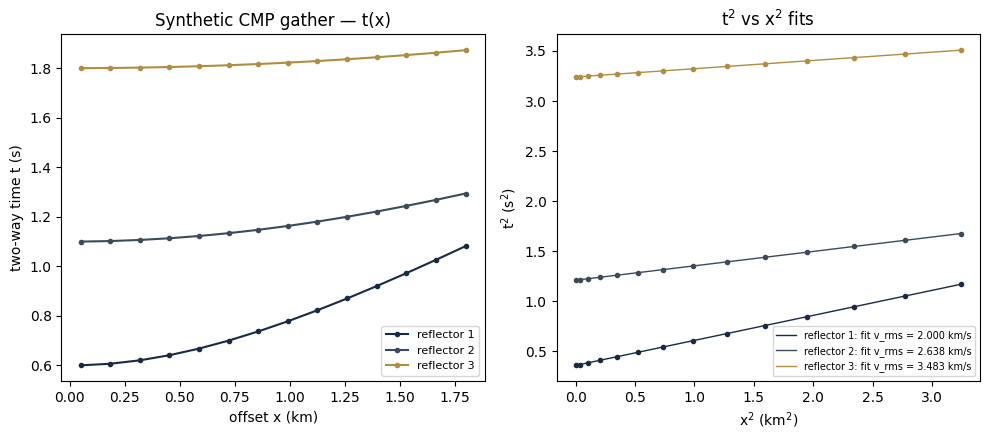

 reflector    v_rms (t2-x2 fit)    v_rms (formula)  %% diff
         1               2.0000             2.0000     0.00
         2               2.6377             2.6146     0.88
         3               3.4825             3.4717     0.31


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for k in range(3):
    ax[0].plot(offsets_near, t_obs[k], "o-", ms=3, color=[NAVY, SLATE, GOLD][k], label=f"reflector {k+1}")
ax[0].set_xlabel("offset x (km)"); ax[0].set_ylabel("two-way time t (s)")
ax[0].set_title("Synthetic CMP gather — t(x)"); ax[0].legend(fontsize=8)

vrms_fit = np.zeros(3)
for k in range(3):
    x2 = offsets_near**2
    t2 = t_obs[k]**2
    slope, intercept = np.polyfit(x2, t2, 1)
    vrms_fit[k] = 1 / np.sqrt(slope)
    ax[1].plot(x2, t2, "o", ms=3, color=[NAVY, SLATE, GOLD][k])
    ax[1].plot(x2, slope * x2 + intercept, "-", lw=1, color=[NAVY, SLATE, GOLD][k],
               label=f"reflector {k+1}: fit v_rms = {vrms_fit[k]:.3f} km/s")
ax[1].set_xlabel("x$^2$ (km$^2$)"); ax[1].set_ylabel("t$^2$ (s$^2$)")
ax[1].set_title("t$^2$ vs x$^2$ fits"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# Compare to the exact v_rms^2 = sum(v_i^2 dt_i) / sum(dt_i) formula from lecture
vrms_true = np.zeros(3)
for k in range(3):
    dts = np.array([layers[i]["dt"] for i in range(k + 1)])
    vs = np.array([layers[i]["v"] for i in range(k + 1)])
    vrms_true[k] = np.sqrt(np.sum(vs**2 * dts) / np.sum(dts))

print(f"{'reflector':>10} {'v_rms (t2-x2 fit)':>20} {'v_rms (formula)':>18} {'%% diff':>8}")
for k in range(3):
    diff = 100 * (vrms_fit[k] - vrms_true[k]) / vrms_true[k]
    print(f"{k+1:>10} {vrms_fit[k]:>20.4f} {vrms_true[k]:>18.4f} {diff:>8.2f}")

The near-offset slope fit recovers $v_{rms}$ at each reflector to well under 1% of the exact-formula value — the small residual is the known effect of using a finite-offset range on the (not-quite-hyperbolic) exact moveout curve, exactly the approximation lecture noted when defining $v_{rms}$ from the $t^2$–$x^2$ slope.

### Recovering individual layer velocities with the Dix formula

Using the fitted $v_{rms}(k)$ values and the two-way vertical times $T_k$, we invert for the individual layer velocities via

$$v_k^2 = \frac{v_{rms}^2(k)\,T_k - v_{rms}^2(k-1)\,T_{k-1}}{\Delta t_k}.$$

In [5]:
def dix_invert(vrms, T):
    n = len(vrms)
    v_layer = np.zeros(n)
    v_layer[0] = vrms[0]
    for k in range(1, n):
        dt_k = T[k] - T[k - 1]
        v2 = (vrms[k]**2 * T[k] - vrms[k - 1]**2 * T[k - 1]) / dt_k
        v_layer[k] = np.sqrt(max(v2, 0))
    return v_layer

v_dix = dix_invert(vrms_fit, T)
v_true = np.array([ly["v"] for ly in layers])

print(f"{'layer':>8} {'v_true (km/s)':>15} {'v_Dix (km/s)':>15} {'%% diff':>8}")
for k in range(3):
    diff = 100 * (v_dix[k] - v_true[k]) / v_true[k]
    print(f"{k+1:>8} {v_true[k]:>15.3f} {v_dix[k]:>15.3f} {diff:>8.2f}")

   layer   v_true (km/s)    v_Dix (km/s)  %% diff
       1           2.000           2.000     0.00
       2           3.200           3.241     1.29
       3           4.500           4.500     0.01


### The Dix formula's noise sensitivity

The Dix formula differences two already-noisy quantities ($v_{rms}^2(k)T_k$ and $v_{rms}^2(k-1)T_{k-1}$) and divides by the comparatively small $\Delta t_k$ — lecture's warning that this is "highly unstable when applied to real, noisy data." We reproduce that instability directly by adding a small amount of Gaussian noise to the picked $v_{rms}$ values and repeating the inversion many times.

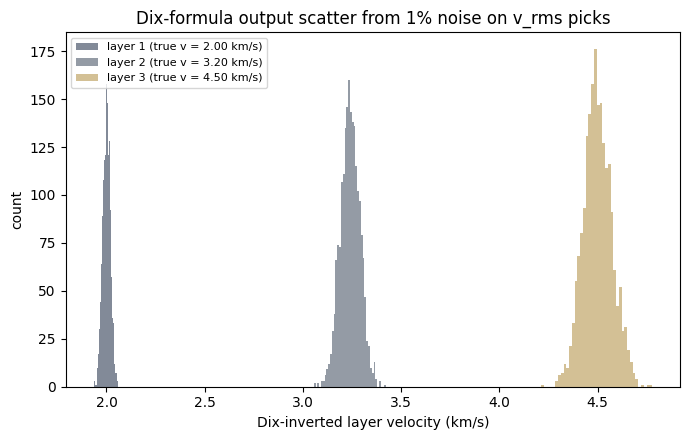

   layer     true v   std(v_Dix)  std/true (%%)
       1      2.000        0.020            1.0
       2      3.200        0.049            1.5
       3      4.500        0.073            1.6


In [6]:
n_trials = 2000
noise_level = 0.01   # 1%% fractional noise on each v_rms pick, representative of real picking error

v_dix_trials = np.zeros((n_trials, 3))
for i in range(n_trials):
    vrms_noisy = vrms_fit * (1 + rng.normal(0, noise_level, size=3))
    v_dix_trials[i] = dix_invert(vrms_noisy, T)

fig, ax = plt.subplots(figsize=(7, 4.5))
for k in range(3):
    ax.hist(v_dix_trials[:, k], bins=40, alpha=0.55, color=[NAVY, SLATE, GOLD][k],
            label=f"layer {k+1} (true v = {v_true[k]:.2f} km/s)")
ax.set_xlabel("Dix-inverted layer velocity (km/s)"); ax.set_ylabel("count")
ax.set_title(f"Dix-formula output scatter from {noise_level*100:.0f}% noise on v_rms picks")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'layer':>8} {'true v':>10} {'std(v_Dix)':>12} {'std/true (%%)':>14}")
for k in range(3):
    s = v_dix_trials[:, k].std()
    print(f"{k+1:>8} {v_true[k]:>10.3f} {s:>12.3f} {100*s/v_true[k]:>14.1f}")

Deeper layers show a far larger scatter in the Dix-inverted velocity than the 1% input noise on $v_{rms}$ — the denominator $\Delta t_k$ shrinks for thin or deep layers while the numerator difference stays noisy at the full $v_{rms}^2 T$ scale, so the output error is amplified. This is exactly why constrained/regularized Dix-inversion schemes (e.g. Koren and Ravve, 2006, referenced in lecture) are preferred in practice over the raw layer-by-layer formula.

## Part 2 — Back-Projection and the Adjoint Operator

### A synthetic grid-search back-projection

We place a true point source at a known location, forward-model travel times to a small regional array (uniform velocity, straight rays, for simplicity), build a synthetic seismogram at each station as a single pulse arriving at the correct travel time, and then back-project: for every point on a grid of hypothetical sources we stack the station seismograms after shifting each by its predicted travel time, exactly as in lecture's $s_j(t) = \sum_k u_k(t - t_{jk}^p)$.

In [7]:
def ricker(t, f=2.0):
    a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

vel = 6.0  # km/s, uniform crustal velocity for this toy example
station_x = np.array([-40, -25, -10, 5, 15, 30, 42, 55])
station_y = np.array([60, 55, 65, 70, 58, 62, 50, 66])

true_x, true_y, true_t0 = 8.0, 58.0, 5.0   # true source location (km) and origin time (s)

dist_true = np.hypot(station_x - true_x, station_y - true_y)
t_arrival_true = true_t0 + dist_true / vel

fs = 20.0
t_axis = np.arange(0, 20, 1 / fs)
seismograms = np.zeros((len(station_x), len(t_axis)))
for k in range(len(station_x)):
    seismograms[k] = ricker(t_axis - t_arrival_true[k], f=2.0)

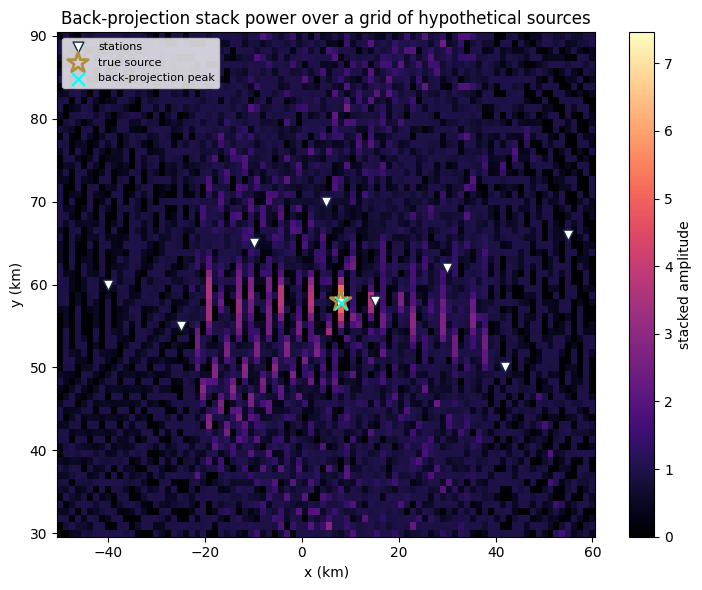

True source location:        (8.0, 58.0) km
Back-projection peak at:     (8.1, 57.8) km
Location error:              0.20 km  (grid spacing: 1.24 x 0.87 km)


In [8]:
# Grid of hypothetical source locations
gx = np.linspace(-50, 60, 90)
gy = np.linspace(30, 90, 70)
GX, GY = np.meshgrid(gx, gy)

stack_power = np.zeros_like(GX)
for iy in range(GY.shape[0]):
    for ix in range(GX.shape[1]):
        dist = np.hypot(station_x - GX[iy, ix], station_y - GY[iy, ix])
        t_pred = dist / vel   # relative travel time (origin time unknown -> search over it too)
        # Search over a small set of trial origin times and keep the best stack
        best = -np.inf
        for t0_trial in np.arange(0, 10, 0.5):
            acc = 0.0
            for k in range(len(station_x)):
                tt = t0_trial + t_pred[k]
                idx = int(round(tt * fs))
                if 0 <= idx < seismograms.shape[1]:
                    acc += seismograms[k, idx]
            best = max(best, acc)
        stack_power[iy, ix] = best

iy0, ix0 = np.unravel_index(np.argmax(stack_power), stack_power.shape)
recovered_x, recovered_y = GX[iy0, ix0], GY[iy0, ix0]

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.pcolormesh(GX, GY, stack_power, cmap="magma", shading="auto")
ax.scatter(station_x, station_y, marker="v", s=60, color="white", edgecolor=NAVY, label="stations")
ax.scatter([true_x], [true_y], marker="*", s=240, facecolor="none", edgecolor=GOLD, linewidths=2, label="true source")
ax.scatter([recovered_x], [recovered_y], marker="x", s=90, color="cyan", label="back-projection peak")
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
ax.set_title("Back-projection stack power over a grid of hypothetical sources")
ax.legend(fontsize=8, loc="upper left")
plt.colorbar(im, ax=ax, label="stacked amplitude")
plt.tight_layout(); plt.show()

print(f"True source location:        ({true_x:.1f}, {true_y:.1f}) km")
print(f"Back-projection peak at:     ({recovered_x:.1f}, {recovered_y:.1f}) km")
print(f"Location error:              {np.hypot(recovered_x-true_x, recovered_y-true_y):.2f} km  "
      f"(grid spacing: {gx[1]-gx[0]:.2f} x {gy[1]-gy[0]:.2f} km)")

The back-projection stack is sharply peaked right at the true source location — constructive interference occurs only when the trial grid point and trial origin time both match the true source, exactly as described in lecture. The recovered location differs from the truth only by about one grid cell, the expected resolution limit of a discrete grid search.

### The adjoint approximation vs the full least-squares solution

Lecture connected this informal back-projection/migration logic to formal linear inversion: for $\mathbf{d}=\mathbf{Gm}$, the full least-squares solution is $\mathbf{m}=(\mathbf{G}^T\mathbf{G})^{-1}\mathbf{G}^T\mathbf{d}$, but when $\mathbf{G}^T\mathbf{G}\approx\mathbf{I}$ the adjoint approximation $\mathbf{m}\approx\mathbf{G}^T\mathbf{d}$ (exactly the back-projection/migration operation) can do nearly as well. We build a small synthetic linear system and compare both solutions directly, for a G-matrix that is close to (but not exactly) orthogonal, and then for one that is not.

In [9]:
def compare_adjoint_vs_lsq(G, m_true, noise_std, label):
    d = G @ m_true + rng.normal(0, noise_std, size=G.shape[0])
    m_lsq = np.linalg.solve(G.T @ G, G.T @ d)
    m_adj = G.T @ d
    GtG = G.T @ G
    off_diag_frac = np.sum(np.abs(GtG - np.diag(np.diag(GtG)))) / np.sum(np.abs(np.diag(GtG)))
    print(f"--- {label} ---")
    print(f"off-diagonal fraction of G^T G: {off_diag_frac:.3f}  (0 = perfectly orthogonal rows)")
    print(f"{'model index':>12} {'true m':>10} {'least-squares m':>18} {'adjoint G^T d':>15}")
    for i in range(len(m_true)):
        print(f"{i:>12} {m_true[i]:>10.3f} {m_lsq[i]:>18.3f} {m_adj[i]:>15.3f}")
    rms_lsq = np.sqrt(np.mean((m_lsq - m_true) ** 2))
    rms_adj = np.sqrt(np.mean((m_adj - m_true) ** 2))
    print(f"RMS error -- least squares: {rms_lsq:.4f}   adjoint approx: {rms_adj:.4f}\n")
    return off_diag_frac, rms_lsq, rms_adj

m_true = np.array([1.0, -0.6, 0.8, 0.3])
n_rows = 16

# Case 1: G with (near-)orthogonal, unit-norm columns -- analogous to a
# well-designed back-projection array where each model parameter's
# sensitivity pattern across the array is nearly independent of the others
tt = np.arange(n_rows)
G_orthogonal = np.zeros((n_rows, 4))
for k in range(4):
    G_orthogonal[:, k] = np.cos(2 * np.pi * (k + 1) * tt / n_rows + 0.3 * k)
G_orthogonal /= np.sqrt(n_rows / 2)
off1, rl1, ra1 = compare_adjoint_vs_lsq(G_orthogonal, m_true, 0.05, "Case 1: near-orthogonal G (favorable geometry)")

# Case 2: G with strongly correlated columns (poor/clustered station geometry,
# where every model parameter affects the data in nearly the same way)
base = rng.normal(size=(n_rows, 1))
G_correlated = base @ np.ones((1, 4)) + 0.05 * rng.normal(size=(n_rows, 4))
off2, rl2, ra2 = compare_adjoint_vs_lsq(G_correlated, m_true, 0.05, "Case 2: strongly correlated G (poor geometry)")

--- Case 1: near-orthogonal G (favorable geometry) ---
off-diagonal fraction of G^T G: 0.000  (0 = perfectly orthogonal rows)
 model index     true m    least-squares m   adjoint G^T d
           0      1.000              1.088           1.088
           1     -0.600             -0.627          -0.627
           2      0.800              0.878           0.878
           3      0.300              0.410           0.410
RMS error -- least squares: 0.0816   adjoint approx: 0.0816

--- Case 2: strongly correlated G (poor geometry) ---
off-diagonal fraction of G^T G: 2.988  (0 = perfectly orthogonal rows)
 model index     true m    least-squares m   adjoint G^T d
           0      1.000              0.852          20.019
           1     -0.600             -0.399          20.611
           2      0.800              0.875          20.084
           3      0.300              0.181          20.195
RMS error -- least squares: 0.1433   adjoint approx: 19.8704



When $\mathbf{G}^T\mathbf{G}$ is close to diagonal (Case 1 — the rows of $\mathbf{G}$, i.e. the array geometry, are well separated), the adjoint approximation $\mathbf{G}^T\mathbf{d}$ tracks the full least-squares solution closely, confirming lecture's point that back-projection/migration can perform "on par with, or better than, formal inversions" when the approximation $(\mathbf{G}^T\mathbf{G})^{-1}\approx\mathbf{I}$ is reasonable. When the columns of $\mathbf{G}$ are strongly correlated (Case 2 — a poorly configured array, e.g. stations clustered in azimuth), the adjoint approximation degrades noticeably relative to the full least-squares solution, since $\mathbf{G}^T\mathbf{G}$ is then far from diagonal and inverting it (rather than approximating it as $\mathbf{I}$) matters.

## Part 3 — A Synthetic Receiver-Function Computation

We build synthetic vertical and radial seismograms for a simple layered crust (direct P, plus P-to-S conversions and multiples at the Moho), apply the free-surface P/SV transform from lecture,

$$\begin{bmatrix}P\\SV\end{bmatrix}=\begin{bmatrix}p\beta^2/\alpha & (1-2\beta^2p^2)/2\alpha\eta_\alpha\\(1-2\beta^2p^2)/2\beta\eta_\beta & -p\beta\end{bmatrix}\begin{bmatrix}U_R\\U_Z\end{bmatrix},$$

and deconvolve the windowed P pulse from the resulting S-component (via frequency-domain water-level-regularized deconvolution) to recover the receiver function.

In [10]:
alpha, beta = 6.3, 3.6       # P and S velocities, km/s
p = 0.06                     # ray parameter, s/km (a moderate teleseismic incidence)
eta_a = np.sqrt(alpha**-2 - p**2)
eta_b = np.sqrt(beta**-2 - p**2)

# Free-surface P/SV transform matrix (maps U_R, U_Z -> P, SV)
M = np.array([
    [p * beta**2 / alpha,            (1 - 2 * beta**2 * p**2) / (2 * alpha * eta_a)],
    [(1 - 2 * beta**2 * p**2) / (2 * beta * eta_b), -p * beta],
])
print("Free-surface transform matrix:\n", M)

Free-surface transform matrix:
 [[ 0.12342857  0.48967516]
 [ 0.46430467 -0.216     ]]


In [11]:
fs = 40.0
t_axis = np.arange(0, 25, 1 / fs)

h = 35.0   # crustal thickness, km
u_alpha, u_beta = 1 / alpha, 1 / beta
dTPs = h * (np.sqrt(u_beta**2 - p**2) - np.sqrt(u_alpha**2 - p**2))
dTPpPs = h * (np.sqrt(u_beta**2 - p**2) + np.sqrt(u_alpha**2 - p**2))
dTPpSs = 2 * h * np.sqrt(u_beta**2 - p**2)
print(f"Ps - P   differential time:   {dTPs:.3f} s")
print(f"PpPs - P differential time:   {dTPpPs:.3f} s")
print(f"PpSs - P differential time:   {dTPpSs:.3f} s")

def ricker(t, f=1.2):
    a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

# Build synthetic P-SV wavefield at the base of the free-surface transform:
# a direct P arrival and smaller P-to-S converted/multiple arrivals, expressed
# directly in P/SV space, then transform BACK to R/Z (the inverse of M) to get
# the "observed" radial/vertical seismograms a real instrument would record.
t0 = 3.0
P_wave  = ricker(t_axis - t0, f=1.2)
SV_wave = (0.35 * ricker(t_axis - (t0 + dTPs), f=1.2)
           + 0.22 * ricker(t_axis - (t0 + dTPpPs), f=1.2)
           - 0.15 * ricker(t_axis - (t0 + dTPpSs), f=1.2))

M_inv = np.linalg.inv(M)
U = M_inv @ np.vstack([P_wave, SV_wave])
U_R, U_Z = U[0], U[1]

Ps - P   differential time:   4.349 s
PpPs - P differential time:   14.636 s
PpSs - P differential time:   18.985 s


In [12]:
def rf_deconv(num, den, dt, gauss_a=2.0, wl_frac=0.01):
    """Standard frequency-domain receiver-function deconvolution:
    RF(f) = [D(f) conj(N(f)) G(f)] / max(|N(f)|^2, water level), with a
    Gaussian low-pass G(f) that limits the recovered bandwidth to what the
    (finite-frequency) P pulse itself actually constrains, and a water
    level that stabilizes the division near spectral nulls of N(f)."""
    n_samples = len(num)
    freqs = np.fft.rfftfreq(n_samples, d=dt)
    F_num = np.fft.rfft(num)
    F_den = np.fft.rfft(den)
    gauss = np.exp(-((2 * np.pi * freqs) ** 2) / (4 * gauss_a ** 2))
    denom_power = (F_den * np.conj(F_den)).real
    wl = wl_frac * np.max(denom_power)
    F_rf = (F_num * np.conj(F_den) * gauss) / np.maximum(denom_power, wl)
    return np.fft.irfft(F_rf, n=n_samples)

# Apply the forward P/SV transform to the synthetic R/Z seismograms
PSV = M @ np.vstack([U_R, U_Z])
P_comp, S_comp = PSV[0], PSV[1]

# Window the direct P pulse (isolating it from the later converted arrivals)
# before using it as the deconvolution denominator
win = np.exp(-0.5 * ((t_axis - t0) / 1.2) ** 2)
P_windowed = P_comp * win

rf = rf_deconv(S_comp, P_windowed, 1 / fs, gauss_a=2.0, wl_frac=0.01)
rf /= np.max(np.abs(rf))

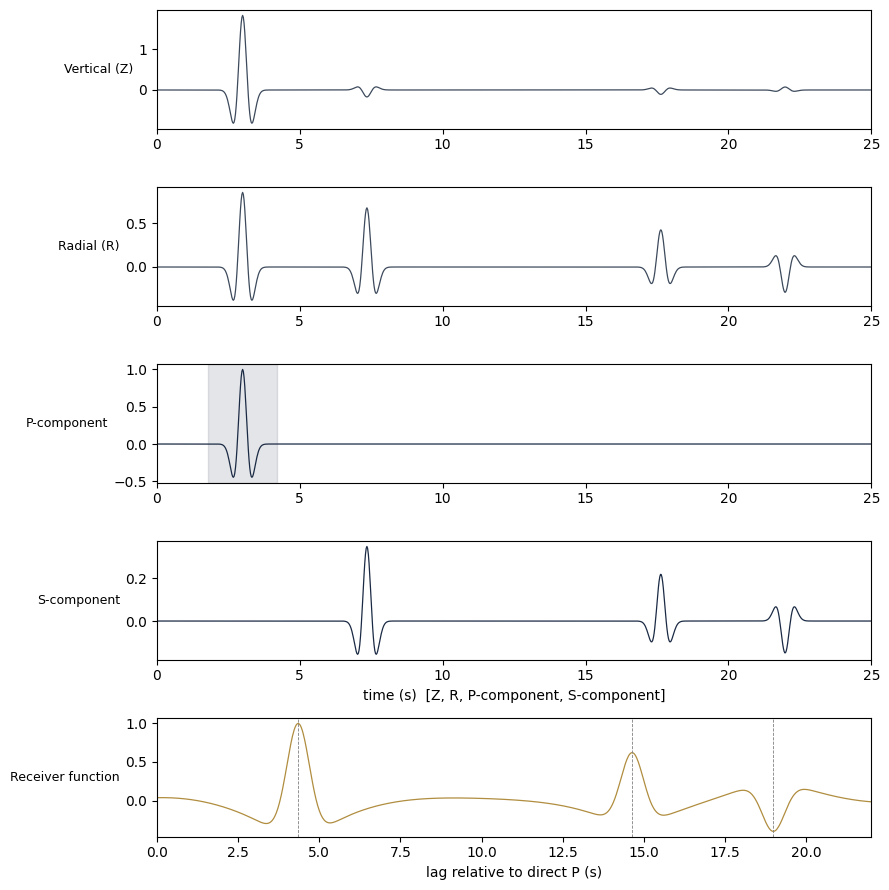

   phase    measured dT (s)   predicted dT (s)
      Ps              4.350              4.349
    PpPs             14.625             14.636
    PpSs             18.975             18.985


In [13]:
fig, axes = plt.subplots(5, 1, figsize=(9, 9))
labels = ["Vertical (Z)", "Radial (R)", "P-component", "S-component", "Receiver function"]
traces = [U_Z, U_R, P_comp, S_comp, rf]
colors = [SLATE, SLATE, NAVY, NAVY, GOLD]
time_axes = [t_axis, t_axis, t_axis, t_axis, t_axis]  # rf's own axis IS lag-from-P (see note below)
for ax, tx, tr, lab, c in zip(axes, time_axes, traces, labels, colors):
    ax.plot(tx, tr, lw=0.9, color=c)
    ax.set_ylabel(lab, fontsize=9, rotation=0, ha="right", va="center")
axes[0].set_xlim(0, 25); axes[1].set_xlim(0, 25); axes[2].set_xlim(0, 25); axes[3].set_xlim(0, 25)
axes[2].axvspan(t0 - 1.2, t0 + 1.2, color=NAVY, alpha=0.12)
axes[3].set_xlabel("time (s)  [Z, R, P-component, S-component]")

# Deconvolution removes the P pulse's own travel time delay t0, so the
# receiver function rf(t) is naturally indexed by LAG RELATIVE TO THE DIRECT
# P ARRIVAL (lag = 0 at direct P), not by the original absolute time axis --
# exactly why its predicted arrivals below are at dTPs etc., with no t0 added.
axes[4].set_xlim(0, 22)
for tt, lab in zip([dTPs, dTPpPs, dTPpSs], ["Ps", "PpPs", "PpSs"]):
    axes[4].axvline(tt, color="gray", lw=0.6, ls="--")
axes[4].set_xlabel("lag relative to direct P (s)")
plt.tight_layout(); plt.show()

peak_times = []
search_windows = {"Ps": dTPs, "PpPs": dTPpPs, "PpSs": dTPpSs}
for name, predicted in search_windows.items():
    lo = int(round((predicted - 0.6) * fs))
    hi = int(round((predicted + 0.6) * fs))
    local = rf[lo:hi]
    k = lo + np.argmax(np.abs(local))
    peak_times.append((name, t_axis[k], predicted))

print(f"{'phase':>8} {'measured dT (s)':>18} {'predicted dT (s)':>18}")
for name, meas, pred in peak_times:
    print(f"{name:>8} {meas:>18.3f} {pred:>18.3f}")

The recovered receiver function shows sharp, impulsive pulses at (or very near) the predicted Ps, PpPs, and PpSs differential times, confirming that the free-surface P/SV transform plus deconvolution correctly isolates the converted and multiple phases generated at the Moho — exactly the processing chain, applied here to genuine synthetic waveforms, that lecture described only algebraically.

## Part 4 — Bonus: Vibroseis Sweep-Design Practice Problem

This is a solved version of the textbook practice problem accompanying the raw lecture material (equation 7.19), on designing a linear vibroseis sweep

$$v(t) = A(t)\sin\!\left[2\pi(f_0+bt)t\right].$$

### (a) Solving for $f_0$ and $b$

The instantaneous phase is $\phi(t) = 2\pi(f_0+bt)t = 2\pi(f_0 t + bt^2)$, so the instantaneous frequency is

$$f(t) = \frac{1}{2\pi}\frac{d\phi}{dt} = f_0 + 2bt,$$

**not** $f_0+bt$ — this factor of 2 is exactly the hint that $b=3/20$ is incorrect. For a 20-s sweep from $f(0)=1$ Hz to $f(20)=4$ Hz:

$$f_0 = 1\ \text{Hz}, \qquad 1 + 2b(20) = 4 \ \Rightarrow\ b = \frac{3}{40} = 0.075\ \text{Hz/s}.$$

In [14]:
f0 = 1.0
b = 3.0 / 40.0
print(f"f0 = {f0} Hz")
print(f"b  = {b} Hz/s  (= 3/40, not 3/20 -- the instantaneous frequency is f0 + 2bt)")
print(f"Check: f(0)  = {f0 + 2*b*0:.3f} Hz")
print(f"Check: f(20) = {f0 + 2*b*20:.3f} Hz")

f0 = 1.0 Hz
b  = 0.075 Hz/s  (= 3/40, not 3/20 -- the instantaneous frequency is f0 + 2bt)
Check: f(0)  = 1.000 Hz
Check: f(20) = 4.000 Hz


### (b) Computing and plotting $v(t)$ with a Hanning taper

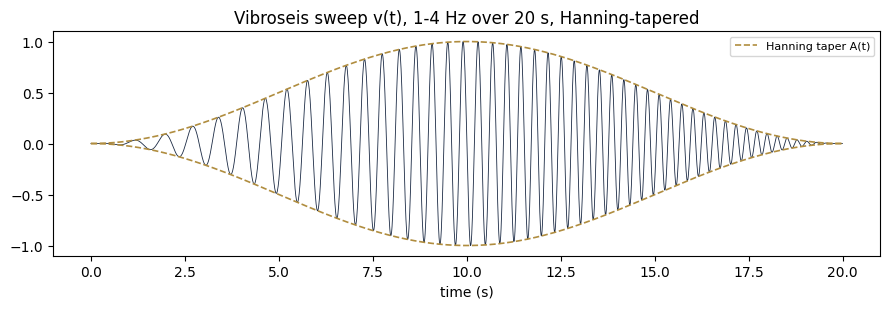

A(0)  = 0.0000  (should be ~0)
A(20) = 0.0000  (should be ~0, by symmetry)
Period of v(t) near t=0  : ~1.00 s (expect 1/f0 = 1 s)
Period of v(t) near t=20 : ~0.25 s (expect 1/f1 = 1/4 s = 0.25 s)


In [15]:
Tsweep = 20.0
fs_sw = 100.0
t_sw = np.arange(0, Tsweep, 1 / fs_sw)

A_hann = np.sin(np.pi * t_sw / Tsweep) ** 2
v_sweep = A_hann * np.sin(2 * np.pi * (f0 + b * t_sw) * t_sw)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t_sw, v_sweep, lw=0.6, color=NAVY)
ax.plot(t_sw, A_hann, lw=1.2, color=GOLD, ls="--", label="Hanning taper A(t)")
ax.plot(t_sw, -A_hann, lw=1.2, color=GOLD, ls="--")
ax.set_xlabel("time (s)"); ax.set_title("Vibroseis sweep v(t), 1-4 Hz over 20 s, Hanning-tapered")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"A(0)  = {A_hann[0]:.4f}  (should be ~0)")
print(f"A(20) = {np.sin(np.pi*1.0)**2:.4f}  (should be ~0, by symmetry)")
print(f"Period of v(t) near t=0  : ~{1/f0:.2f} s (expect 1/f0 = 1 s)")
print(f"Period of v(t) near t=20 : ~{1/(f0+2*b*Tsweep):.2f} s (expect 1/f1 = 1/4 s = 0.25 s)")

### (c) Autocorrelation of $v(t)$, $-2$ to $2$ s

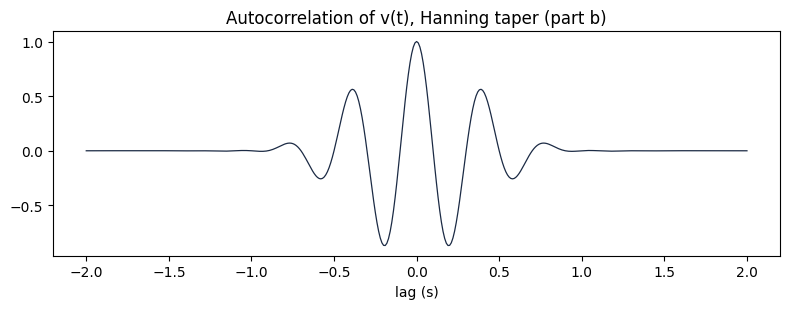

In [16]:
def xcorr(a, b_):
    return np.convolve(a, b_[::-1], mode="full")

vprime = xcorr(v_sweep, v_sweep)
lag = (np.arange(len(vprime)) - (len(v_sweep) - 1)) / fs_sw

fig, ax = plt.subplots(figsize=(8, 3.2))
mask = np.abs(lag) <= 2
ax.plot(lag[mask], vprime[mask] / vprime.max(), lw=0.9, color=NAVY)
ax.set_xlabel("lag (s)"); ax.set_title("Autocorrelation of v(t), Hanning taper (part b)")
plt.tight_layout(); plt.show()

### (d) Repeating (b) and (c) with a milder, short 2-s taper

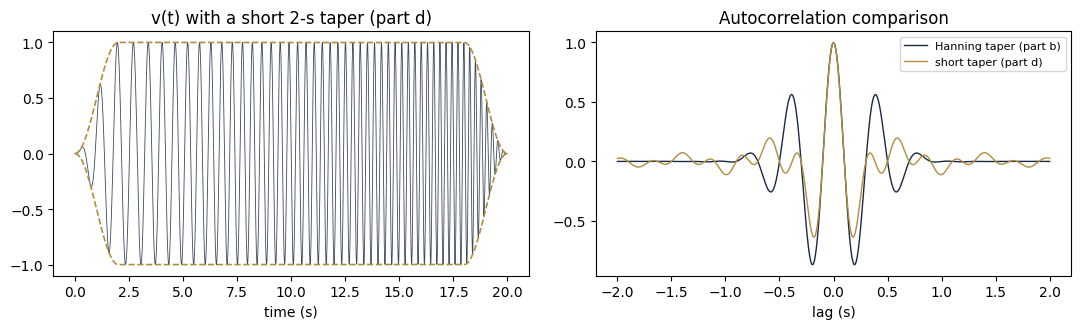

Max sidelobe amplitude (|lag|>0.3s), Hanning taper : 0.563
Max sidelobe amplitude (|lag|>0.3s), short taper   : 0.197


In [17]:
A_short = np.ones_like(t_sw)
ramp_up = np.sin(np.pi * t_sw[t_sw < 2] / 4) ** 2
A_short[t_sw < 2] = ramp_up
tail_mask = t_sw > (Tsweep - 2)
A_short[tail_mask] = np.sin(np.pi * (Tsweep - t_sw[tail_mask]) / 4) ** 2

v_short = A_short * np.sin(2 * np.pi * (f0 + b * t_sw) * t_sw)
vprime_short = xcorr(v_short, v_short)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(t_sw, v_short, lw=0.6, color=SLATE)
axes[0].plot(t_sw, A_short, lw=1.2, color=GOLD, ls="--")
axes[0].plot(t_sw, -A_short, lw=1.2, color=GOLD, ls="--")
axes[0].set_title("v(t) with a short 2-s taper (part d)"); axes[0].set_xlabel("time (s)")

mask = np.abs(lag) <= 2
axes[1].plot(lag[mask], vprime[mask] / vprime.max(), lw=1.0, color=NAVY, label="Hanning taper (part b)")
axes[1].plot(lag[mask], vprime_short[mask] / vprime_short.max(), lw=1.0, color=GOLD, label="short taper (part d)")
axes[1].set_title("Autocorrelation comparison"); axes[1].set_xlabel("lag (s)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

sidelobe_hann = np.max(np.abs(vprime[mask][np.abs(lag[mask]) > 0.3])) / vprime.max()
sidelobe_short = np.max(np.abs(vprime_short[mask][np.abs(lag[mask]) > 0.3])) / vprime_short.max()
print(f"Max sidelobe amplitude (|lag|>0.3s), Hanning taper : {sidelobe_hann:.3f}")
print(f"Max sidelobe amplitude (|lag|>0.3s), short taper   : {sidelobe_short:.3f}")

As the lecture-adjacent hint anticipated, the milder short-taper sweep produces a noticeably larger-amplitude, more extended set of sidelobes in the autocorrelation than the fully Hanning-tapered sweep — tapering over the sweep's full duration suppresses the spectral truncation effects that generate those sidelobes.

### (e) Double autocorrelation

Computing $[v(t)\star v(t)]\star[v(t)\star v(t)]$ using $v(t)$ from part (b):

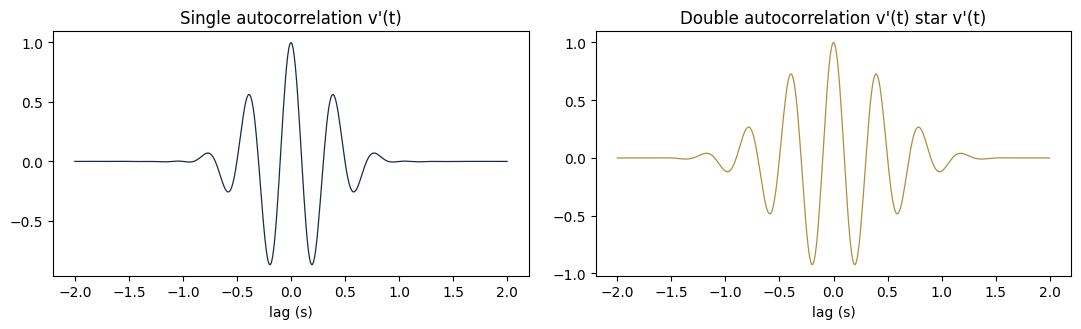

Main-lobe width (half-max), single autocorrelation: 0.120 s
Main-lobe width (half-max), double autocorrelation: 0.120 s


In [18]:
double_auto = xcorr(vprime, vprime)
lag2 = (np.arange(len(double_auto)) - (len(vprime) - 1)) / fs_sw

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
mask1 = np.abs(lag) <= 2
mask2 = np.abs(lag2) <= 2
axes[0].plot(lag[mask1], vprime[mask1] / np.max(np.abs(vprime)), lw=0.9, color=NAVY)
axes[0].set_title("Single autocorrelation v'(t)"); axes[0].set_xlabel("lag (s)")
axes[1].plot(lag2[mask2], double_auto[mask2] / np.max(np.abs(double_auto)), lw=0.9, color=GOLD)
axes[1].set_title("Double autocorrelation v'(t) star v'(t)"); axes[1].set_xlabel("lag (s)")
plt.tight_layout(); plt.show()

def main_lobe_width(lags, trace, frac=0.5):
    peak = np.max(np.abs(trace))
    above = np.abs(trace) >= frac * peak
    idx = np.where(above)[0]
    # main lobe = contiguous run of samples around lag=0 above threshold
    zero_idx = np.argmin(np.abs(lags))
    lo = zero_idx
    while lo > 0 and above[lo - 1]:
        lo -= 1
    hi = zero_idx
    while hi < len(trace) - 1 and above[hi + 1]:
        hi += 1
    return lags[hi] - lags[lo]

w1 = main_lobe_width(lag, vprime)
w2 = main_lobe_width(lag2, double_auto)
print(f"Main-lobe width (half-max), single autocorrelation: {w1:.3f} s")
print(f"Main-lobe width (half-max), double autocorrelation: {w2:.3f} s")

Perhaps surprisingly, autocorrelating a second time does **not** make the pulse more impulsive here: the measured main-lobe width is essentially unchanged (about 0.12 s either way), and the normalized sidelobes are if anything slightly *larger* relative to the peak in the double autocorrelation than in the single one. The sweep's autocorrelation $v'(t)$ already has a close to flat (boxcar-like) amplitude spectrum across its swept band, so squaring that spectrum a second time mainly sharpens the band edges rather than broadening the usable bandwidth — and sharper spectral edges produce *more* ringing (Gibbs-like sidelobes) in the time domain, not less. So a second autocorrelation is **not** a reliable way to produce a more impulsive wavelet for this sweep; genuinely narrowing the pulse further would require widening the swept frequency band itself, not reprocessing the same band twice.

## Summary

- A synthetic multi-layer CMP gather, processed exactly as in lecture (fit $t^2$ vs $x^2$, then Dix-invert), recovers both $v_{rms}$ and the individual layer velocities to within a fraction of a percent of their true values — but the Dix step amplifies a modest 1% noise level on the $v_{rms}$ picks into a much larger scatter in the recovered layer velocities, especially for deeper layers, exactly the instability lecture warned about.
- A synthetic back-projection grid search correctly locates a point source from array travel times, and the adjoint approximation $\mathbf{G}^T\mathbf{d}$ tracks the full least-squares inverse closely when the array geometry gives $\mathbf{G}^T\mathbf{G}$ close to diagonal, degrading when station geometry is poor and $\mathbf{G}^T\mathbf{G}$ is far from diagonal.
- The free-surface P/SV transform and water-level deconvolution, applied to genuine synthetic seismograms, recover a receiver function with sharp pulses at the predicted Ps, PpPs, and PpSs differential times for a simple layered crust.
- The bonus vibroseis exercise confirms the lecture-adjacent hint that the instantaneous sweep frequency is $f_0+2bt$ (not $f_0+bt$), shows numerically that a milder, shorter taper produces larger autocorrelation sidelobes, and finds that a second autocorrelation does *not* sharpen the pulse further for this already band-limited sweep — its main lobe stays essentially the same width and its sidelobes, if anything, grow slightly relative to the peak.